In [ ]:
from datetime import datetime, timezone
import catalogo as cat
import funciones_base as fb
import analisis as an
import satelite as sat
import matplotlib.pyplot as plt
from analisis import resumen_por_grupo
from analisis import en_zona, ordenar_por

Matplotlib is building the font cache; this may take a moment.


## 1. Carga de datos

Se lee el archivo `datos/satelites.json` y se calcula la fecha media de los datos con `epoch_medio`. Luego se crean los objetos `Satelite` para un momento de cálculo y se cuenta cuántos registros descarta `crear_satelites` (los que están por debajo de 100 km de altitud).

In [11]:
registros = cat.leer_satelites("datos/satelites.json")
epoch = fb.epoch_medio(registros)
momento = datetime.now(timezone.utc)
satelites = sat.crear_satelites(registros, momento)

print(f"Satélites en el archivo: {len(registros)}")
print(f"Fecha media de los datos (epoch_medio): {epoch}")
print(f"Momento del cálculo: {momento}")
print(f"Días transcurridos: {(momento - epoch).days}")
print(f"Satélites descartados por crear_satelites: {len(registros) - len(satelites)}")


Satélites en el archivo: 16822
Fecha media de los datos (epoch_medio): 2026-10-27 00:56:47.794606+00:00
Momento del cálculo: 2026-10-29 17:00:44.683224+00:00
Días transcurridos: 2
Satélites descartados por crear_satelites: 0


## 2. Grupos

Se cuenta cuántos satélites pertenecen a cada grupo (Starlink, OneWeb, GPS, etc.) con `contar_por_grupo`, y se calcula qué porcentaje del total es Starlink.

In [5]:
conteo_grupos = cat.contar_por_grupo(registros)

for nombre, cantidad in sorted(conteo_grupos.items(), key=lambda par: par[1], reverse=True):
    print(f"{nombre}: {cantidad}")

porcentaje_starlink = conteo_grupos["Starlink"] / len(registros) * 100
print(f"\nStarlink representa el {porcentaje_starlink:.1f} % del total")

Starlink: 11160
Otros: 4152
OneWeb: 651
Kuiper: 391
Qianfan: 257
Iridium: 80
BeiDou: 55
GPS: 40
Globalstar: 36

Starlink representa el 66.3 % del total


## 3. Lanzamientos por año

Se cuenta cuántos de los satélites activos hoy fueron lanzados cada año desde 2015, con `lanzamientos_por_anio`, y se identifica el año con más lanzamientos.

In [4]:
por_anio = cat.lanzamientos_por_anio(registros)
desde_2015 = {anio: n for anio, n in sorted(por_anio.items()) if anio >= 2015}

for anio, cantidad in desde_2015.items():
    print(f"{anio}: {cantidad}")

anio_max = max(desde_2015, key=desde_2015.get)
print(f"\nAño con más lanzamientos: {anio_max} ({desde_2015[anio_max]} satélites)")

2015: 96
2016: 84
2017: 136
2018: 193
2019: 144
2020: 354
2021: 987
2022: 1715
2023: 2260
2024: 2428
2025: 4289
2026: 3421

Año con más lanzamientos: 2025 (4289 satélites)


# 4. Tipos de órbita

Se realiza el conteo de satélites según su tipo de órbita (LEO, MEO, GEO, HEO) utilizando la función `contar_por_tipo` del módulo `analisis`.

In [6]:
conteo_orbitas = an.contar_por_tipo(satelites)

for tipo, cantidad in conteo_orbitas.items():
    print(f"{tipo}: {cantidad}")

LEO: 16011
MEO: 197
GEO: 598
HEO: 16


# 5. Extremos

Se identifican el satélite más bajo, el más alto y el top 10 de cada extremo mediante las funciones `mas_bajo`, `mas_alto` y `top_n` del módulo `analisis`, imprimiendo la información de cada objeto a través de su método `__str__`.

In [7]:
sat_mas_bajo = an.mas_bajo(satelites)
sat_mas_alto = an.mas_alto(satelites)

print("Satélite más bajo:")
print(sat_mas_bajo)

print("\nSatélite más alto:")
print(sat_mas_alto)

top_10_bajos = an.top_n(satelites, 10, mas_altos=False)
top_10_altos = an.top_n(satelites, 10, mas_altos=True)

print("\nTop 10 más bajos:")
for sat in top_10_bajos:
    print(sat)

print("\nTop 10 más altos:")
for sat in top_10_altos:
    print(sat)

Satélite más bajo:
RASSVET-3 23 | LEO | 100.041 km

Satélite más alto:
CXO | HEO | 133652.26 km

Top 10 más bajos:
RASSVET-3 23 | LEO | 100.041 km
STARLINK-1036 | LEO | 111.946 km
IPERDRONE.0 | LEO | 131.824 km
RASSVET-3 17 | LEO | 179.065 km
STARLINK-1309 | LEO | 185.076 km
ZHUQUE-2E R/B | LEO | 197.581 km
IOD-1 | LEO | 212.942 km
STARLINK-1283 | LEO | 215.023 km
STARLINK-1327 | LEO | 226.075 km
STARLINK-30233 | LEO | 234.751 km

Top 10 más altos:
CXO | HEO | 133652.26 km
SMILE | HEO | 86354.49 km
THEMIS E | HEO | 77896.32 km
THEMIS D | HEO | 60117.283 km
XMM-NEWTON | HEO | 53628.941 km
PROBA-3 OSC | HEO | 48583.22 km
PROBA-3 CSC | HEO | 48582.758 km
2026-167B | HEO | 47112.846 km
ASBM-2 | HEO | 43774.284 km
COSMOS 2590 | HEO | 42637.374 km


## 6. Comparación de grupos

Resumen de altitudes (en km) de cada grupo: cantidad de satélites, altitud mínima, media y máxima.

In [8]:

resumen = resumen_por_grupo(satelites)

print("Grupo | Cantidad | Mínima (km) | Media (km) | Máxima (km)")
print("-----------------------------------------------------")

for nombre in resumen:
    datos = resumen[nombre]
    print(nombre, "|", datos["cantidad"], "|", datos["minima"], "|", datos["media"], "|", datos["maxima"])

Grupo | Cantidad | Mínima (km) | Media (km) | Máxima (km)
-----------------------------------------------------
Otros | 4070 | 102.53 | 6465.11596977887 | 338363.637
GPS | 40 | 19693.984 | 20228.259525 | 21033.546
Globalstar | 36 | 681.149 | 1292.2944444444445 | 1839.192
BeiDou | 55 | 21487.49 | 27246.338309090912 | 36356.103
Iridium | 80 | 632.63 | 776.6091250000001 | 807.488
OneWeb | 651 | 533.88 | 1209.604559139785 | 1251.846
Starlink | 11107 | 101.546 | 468.11392320158456 | 596.093
Qianfan | 257 | 800.58 | 1044.2050311284047 | 1235.445
Kuiper | 391 | 442.259 | 632.129800511509 | 654.164


## 7. Satélites sobre Bariloche

Se cuentan los satélites que están dentro de la zona BARILOCHE en el momento del cálculo y se los lista de menor a mayor altitud.

La zona es un rectángulo definido por cuatro límites (longitud mínima, latitud mínima, longitud máxima y latitud máxima). Los límites se obtuvieron dibujando el rectángulo sobre el mapa en http://bboxfinder.com, cuyo campo "Box" muestra los cuatro valores en ese mismo orden.

In [9]:
BARILOCHE = (-76.30, -46.13, -66.30, -36.13)   # lon_min, lat_min, lon_max, lat_max

sobre_bariloche = en_zona(satelites, BARILOCHE)
ordenados = ordenar_por(sobre_bariloche, "altitud_km")

print("Satélites sobre Bariloche:", len(ordenados))
print("Ordenados de menor a mayor altitud:")
print("-----------------------------------")

for sat in ordenados:
    print(sat)

Satélites sobre Bariloche: 57
Ordenados de menor a mayor altitud:
-----------------------------------
STARLINK-11379 [DTC] | LEO | 343.791 km
STARLINK-11654 [DTC] | LEO | 350.573 km
STARLINK-11732 [DTC] | LEO | 357.121 km
STARLINK-11273 [DTC] | LEO | 374.312 km
REAL | LEO | 466.884 km
STARLINK-31521 | LEO | 470.971 km
STARLINK-35530 | LEO | 471.444 km
STARLINK-35601 | LEO | 472.969 km
STARLINK-34817 | LEO | 473.206 km
STARLINK-37890 | LEO | 474.694 km
STARLINK-34244 | LEO | 474.949 km
STARLINK-2466 | LEO | 476.087 km
STARLINK-30580 | LEO | 476.316 km
STARLINK-32203 | LEO | 476.674 km
STARLINK-3875 | LEO | 477.884 km
STARLINK-32012 | LEO | 478.087 km
STARLINK-3195 | LEO | 478.202 km
STARLINK-36282 | LEO | 480.252 km
STARLINK-5428 | LEO | 484.658 km
STARLINK-36551 | LEO | 492.277 km
STARLINK-35879 | LEO | 492.939 km
STARLINK-35992 | LEO | 493.551 km
STARLINK-35650 | LEO | 493.657 km
STARLINK-35692 | LEO | 494.583 km
STARLINK-34158 | LEO | 494.665 km
STARLINK-6334 | LEO | 494.719 km
STARL

# 8. Conclusiones

Se genera un párrafo integrador utilizando el estado y las variables ya calculadas en los puntos anteriores (grupos del punto 6, año del punto 3, tipo de órbita del punto 4 y satélites sobre Bariloche del punto 7).

In [10]:
#1 Grupo que predomina reutiliza 'resumen' del punto 6.
grupo_predominante = list(resumen.keys())[0]
for g in resumen:
    if resumen[g]["cantidad"] > resumen[grupo_predominante]["cantidad"]:
        grupo_predominante = g

#2 Año con más lanzamientos asigna la variable 'anio_max' calculada en el punto 3.
anio_predominante = anio_max

#3 Tipo de órbita que predomina reutiliza 'conteo_orbitas' del punto 4.
orbita_predominante = list(conteo_orbitas.keys())[0]
for orb in conteo_orbitas:
    if conteo_orbitas[orb] > conteo_orbitas[orbita_predominante]:
        orbita_predominante = orb

#4 Satélites sobre Bariloche (reutiliza 'sobre_bariloche' del punto 7.
cant_bariloche = len(sobre_bariloche)


# Párrafo integrador final
parrafo = (
    f"En conclusión, el grupo de satélites que predomina es {grupo_predominante}.\n"
    f"El año en el que se lanzaron más satélites fue {anio_predominante},\n"
    f"mientras que el tipo de órbita predominante es {orbita_predominante}.\n"
    f"Por último, se registraron un total de {cant_bariloche} satélites sobre la zona de Bariloche."
)

print(parrafo)

En conclusión, el grupo de satélites que predomina es Starlink.
El año en el que se lanzaron más satélites fue 2025,
mientras que el tipo de órbita predominante es LEO.
Por último, se registraron un total de 57 satélites sobre la zona de Bariloche.


# 9. Lanzamientos en el tiempo

Se genera un gráfico de barras en donde el eje X son las llaves del diccionario y el eje Y son los valores del diccionario 'Lanzamientos_por_anio'

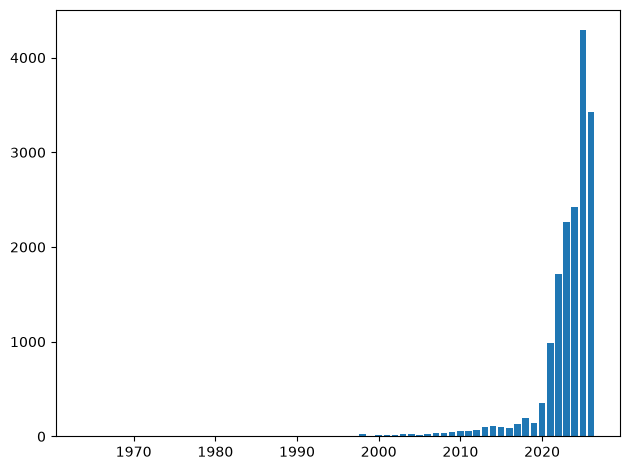

In [17]:
datos = cat.lanzamientos_por_anio(registros)

categorias = list(datos.keys())
valores = list(datos.values())

barras = plt.bar(categorias, valores)

plt.tight_layout()
plt.show()